In [35]:
#Import the main libraries we use
import pandas as pd
import numpy as np
import datetime

In [94]:
from pathlib import Path

ROOT =Path(r"C:\Users\luked\OneDrive\Documents\Grateful Dead")

DATA_DIR = ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
SQL_OUTPUT_DIR = DATA_DIR / "sql_outputs"


PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
SQL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


We import the data which has been obtained from a grateful dead archiving website called Jerry Base which lets you directly download the data to a CSV file. This original file was very messy, concatenating many rows together and containing many errors. I used Claude AI to remedy much of this by converting it into a neater file that is the one that is imported below. The following cleaning steps will take this still quite messy dataframe and clean it so we can run some analysis on it. 

In [37]:
full_gd_setlists = pd.read_csv(
    RAW_DATA_DIR / "jerrybase_setlists_precleaned.csv"
)
print(full_gd_setlists)

                   date                             venue        set_label  \
0      1965-12-11 [Sat]  Muir Beach Lodge, Muir Beach, CA      Known Songs   
1      1965-12-11 [Sat]  Muir Beach Lodge, Muir Beach, CA      Known Songs   
2      1965-12-11 [Sat]  Muir Beach Lodge, Muir Beach, CA      Known Songs   
3      1965-12-18 [Sat]  The Big Beat Club, Palo Alto, CA      Partial Set   
4      1966-01-00 [Sat]        Bear's House, Berkeley, CA  Partial Session   
...                 ...                               ...              ...   
40497  1995-07-09 [Sun]        Soldier Field, Chicago, IL            Set 2   
40498  1995-07-09 [Sun]        Soldier Field, Chicago, IL            Set 2   
40499  1995-07-09 [Sun]        Soldier Field, Chicago, IL            Set 2   
40500  1995-07-09 [Sun]        Soldier Field, Chicago, IL           Encore   
40501  1995-07-09 [Sun]        Soldier Field, Chicago, IL           Encore   

       position_in_set                       song  is_segue_int

The next block removes sets where the data from jerry base contains an invalid date, seemingly relating to incomplete sessions. We also reformat the date to a format that is recognised in SQL which will come in very handy later. 

In [38]:
#Filters out sets from invalid dates
mask=~(full_gd_setlists['date'].str.contains('-00'))
gd_setlists=full_gd_setlists[mask]
cleaned_dates = gd_setlists['date'].str.split().str[0]
gd_setlists['date'] = pd.to_datetime(cleaned_dates, format='%Y-%m-%d').dt.strftime('%Y-%m-%d')

We use AI to search through the file and find any songs that flag as potential parsing errors. The following few blocks of code sort through these manually, removing the songs that are genuine errors, removing the trailing infromation from some songs that contain extra information and keeping songs that just have long titles and were flagged wrongly.

In [39]:
mask=gd_setlists['possible_parsing_issue']==True
issues=gd_setlists[mask]
weirdsongs=issues.groupby('song').count()
print(weirdsongs)

                                                    date  venue  set_label  \
song                                                                         
A Voice From On High New Riders set was between...     1      1          1   
Black Peter New Riders set was between the acou...     2      2          2   
Brokedown Palace New Riders set was between the...     1      1          1   
Candyman New Riders set was between the acousti...     1      1          1   
Cumberland Blues New Riders set was between the...     1      1          1   
Electric:  Good Morning Little Schoolgirl              1      1          1   
Gathering Flowers For The Master's Bouquet             1      1          1   
It Takes A Lot To Laugh It Takes A Train To Cry        8      8          8   
Jordan New Riders set was between the acoustic ...     2      2          2   
Mama Tried After the songs listed here there is...     1      1          1   
Non-Improvisation  GD left stage and Foss perfo...     1      1 

In [40]:
#Removes weird songs and creates a list of songs to be replaced with their actual titles
songs=list(weirdsongs.index)
actuallyweird=[songs[10],songs[18],songs[19],songs[20],songs[21]]
other_replaces=[songs[0],songs[1],songs[2],songs[3],songs[4],songs[5],songs[8],songs[9],songs[12],songs[13],songs[14],songs[15],songs[16],songs[17]]
mask=~(gd_setlists['song'].isin(actuallyweird))
gd_setlists=gd_setlists[mask]

In [41]:
#Replaces songs with the actual titles
replace_map = {
    other_replaces[0]: 'A Voice From On High',
    other_replaces[1]: 'Black Peter',
    other_replaces[2]: 'Brokedown Palace',
    other_replaces[3]: 'Candyman',
    other_replaces[4]: 'Cumberland Blues',
    other_replaces[5]: 'Good Morning Little Schoolgirl',
    other_replaces[6]: 'Jordan',
    other_replaces[7]: 'Mama Tried',
    other_replaces[8]: 'Swing Low Sweet Chariot',
    other_replaces[9]: 'Turn On Your Lovelight',
    other_replaces[10]: 'Turn On Your Lovelight',
    other_replaces[11]: "Uncle John's Band",
    other_replaces[12]: "Uncle John's Band",
    other_replaces[13]: "Uncle John's Band"
}
# Apply the replacement directly to the 'song' column
gd_setlists['song'] = gd_setlists['song'].replace(replace_map)
print(gd_setlists['song'].value_counts().head(40))


song
Drums                       1783
Space                       1250
Playing In The Band          755
The Other One                667
Not Fade Away                661
Me And My Uncle              641
Sugar Magnolia               610
China Cat Sunflower          579
I Know You Rider             574
Truckin'                     543
Good Lovin'                  538
Jack Straw                   487
Mexicali Blues               444
Tennessee Jed                442
Minglewood Blues             439
Promised Land                436
Turn On Your Lovelight       432
Deal                         429
Around And Around            422
Looks Like Rain              420
Bertha                       408
El Paso                      401
Wharf Rat                    400
Big River                    400
Estimated Prophet            392
Eyes Of The World            386
Uncle John's Band            371
Sugaree                      365
Samson And Delilah           364
Black Peter                  356
Loser

We now remove the possible parsing issue column as this is no longer relevant.

In [42]:
gd_setlists=gd_setlists.drop('possible_parsing_issue',axis=1)

We remove songs starting with electric and acoustic that are in fact just normal songs mentioned elsewhere.

In [43]:
gd_setlists['song'] = gd_setlists['song'].str.replace('Electric: ', '')
gd_setlists['song'] = gd_setlists['song'].str.replace('Electric:  ', '') 
gd_setlists['song'] = gd_setlists['song'].str.replace('Acoustic: ', '')
gd_setlists['song'] = gd_setlists['song'].str.replace('Acoustic:  ', '')

gd_setlists['song'] = gd_setlists['song'].str.replace(' NRPS', '')
#Removes instance of bad capitalization.
gd_setlists['song'] = gd_setlists['song'].str.replace('Around and Around', 'Around And Around')
#Removes any rogue spaces around the song titles
gd_setlists['song'] = gd_setlists['song'].str.strip()

Removes sessions and soundchecks from the data as they weren't performed for a live audience.

In [44]:
mask=~((gd_setlists['set_label']=='Session')|(gd_setlists['set_label']=='Soundcheck')|(gd_setlists['set_label']=='Partial Session')|\
(gd_setlists['set_label']=='Partial Soundcheck')|(gd_setlists['set_label']=='Acoustic Soundcheck')| (gd_setlists['set_label']=='Electric Session'))
gd_setlists=gd_setlists[mask]

We Remove songs labelled as unidentified

In [45]:
mask= ~(gd_setlists['song'].str.startswith('unidentified-'))
gd_setlists=(gd_setlists[mask])

We then sort out situations where different sets on the same day are labelled as just one big set.
This could have led to problems where songs between sets are treated as transitioning from one to the other.

In [46]:
def add_true_set_sequence(df):
    df = df.sort_values(['date', 'venue']).copy()
    
    is_new_set = (df['position_in_set'] == 1)
    
    is_new_show = (df['date'] != df['date'].shift()) | (df['venue'] != df['venue'].shift())
    
    starts_new_set = is_new_set | is_new_show
    
    df['true_set_sequence_global'] = starts_new_set.cumsum()
    
    df['true_set_sequence'] = df.groupby(['date', 'venue'])['true_set_sequence_global'].transform(
        lambda x: x.rank(method='dense').astype(int)
    )
    df = df.drop(columns='true_set_sequence_global')
    return df

gd_setlists = add_true_set_sequence(gd_setlists)

We split the dataset into two. One contains all of the songs performed and the other contains only songs from full sets, needed for the markov analysis. This is an important distinction as the markov analysis relies on us knowing the exact order each song 

In [47]:
mask=~((gd_setlists['set_label']=='Partial Show')|(gd_setlists['set_label']=='Known Songs')|(gd_setlists['set_label']=='Partial Set 1')|\
(gd_setlists['set_label']=='Partial Set 2')|(gd_setlists['set_label']=='Partial Set')|(gd_setlists['set_label']=='Partial Electric Set')|\
(gd_setlists['set_label']=='Partial Acoustic Set')|(gd_setlists['set_label']=='Partial Electric Set 2')|(gd_setlists['set_label']=='Partial Set 3')|\
(gd_setlists['set_label']=='Partial Acoustic Set 1'))
gd_setlists_markov=gd_setlists[mask]

We download these now cleaned files as csv's which we then import into SQL to get aggregrate tables that will come in very useful.

In [48]:
gd_setlists.to_csv(
    PROCESSED_DATA_DIR / "gd_setlists_cleaned.csv",
    index=False
)

gd_setlists_markov.to_csv(
    PROCESSED_DATA_DIR / "gd_setlists_cleaned_markov.csv",
    index=False
)

We import various tables that we used SQL to create. These SQL queries and tables can be found in this github repository. While in SQL, we grouped the setlists by era of the band. This is not an esy task, considering the grateful dead were constantly evolving and could play vastly different styles of set within a very short period. Ultimately, I decided to group the eras by their keyboardist, as this lineup shift is an easy way of showing the band changing directions. As such the time periods that each period relates to is:

1.)Pigpen Era- 1965- August 26 1971 

2.)Keith Godchaux Era- August 26 1971- February 17 1979 

3.)Brent Mydland Era- April 22 1979- July 23 1990 

4.)Vince Welnick Era- September 7 1990- 1995

In [49]:
#Importing the tables that we used SQL to derive
top_20 = pd.read_csv(
    SQL_OUTPUT_DIR / "Top 20 Songs All Time.csv"
)

top_10_by_year = pd.read_csv(
    SQL_OUTPUT_DIR / "Top 10 Songs of each year.csv"
)

songs_by_era = pd.read_csv(
    SQL_OUTPUT_DIR / "dead_songs_by_era.csv"
)

In [50]:
#We import the libraries we'll use for our plots
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
#Removes a song that seems to have been missed during data cleaning
mask=~(gd_setlists['song']=='see shnid 6171')
gd_setlists=gd_setlists[mask]

mask=~(gd_setlists_markov['song']=='see shnid 6171')
gd_setlists_markov=gd_setlists_markov[mask]

mask=~(songs_by_era['song']=='see shnid 6171')
songs_by_era=songs_by_era[mask]

We create a barplot of the top 20 songs the Grateful Dead played over their entire career.

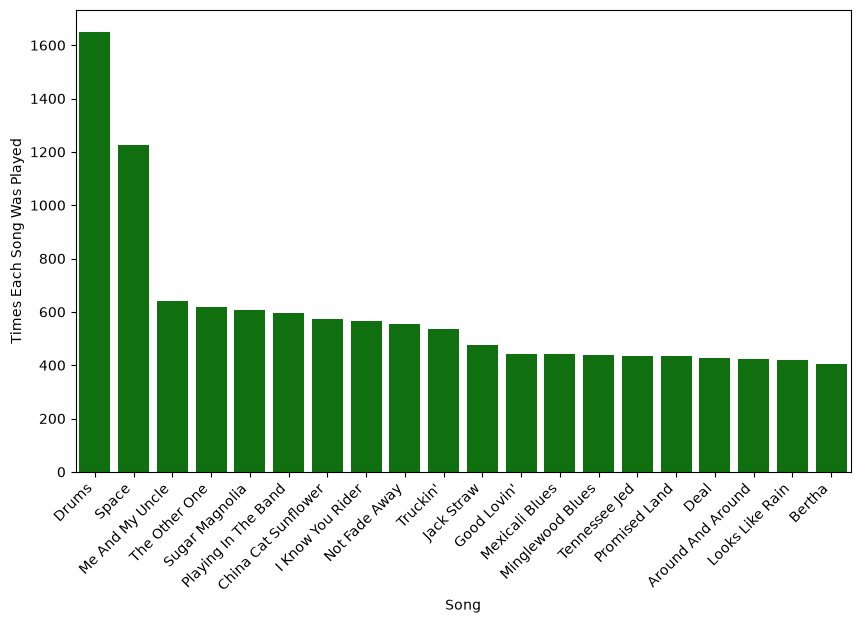

In [52]:
top20=plt.figure(figsize=(10,6))
sns.barplot(data=top_20, x='song', y='song_count',color='Green')
plt.ylabel('Times Each Song Was Played')
plt.xlabel('Song')
plt.xticks(rotation=45, ha='right')
plt.show()

In [53]:
print(top_10_by_year)

     year                       song  show_count  rank
0    1965  Death Don't Have No Mercy           1     1
1    1965           Hog For You Baby           1     1
2    1965                   Tastebud           1     1
3    1965              Midnight Hour           1     1
4    1966   Beat It On Down The Line          13     1
..    ...                        ...         ...   ...
334  1995            Lazy River Road          12     4
335  1995               Easy Answers          11     7
336  1995              Not Fade Away          11     7
337  1995                        Jam          11     7
338  1995              Promised Land          11     7

[339 rows x 4 columns]


We define a function that, when called, plots the top 10 songs played in that year.

In [54]:
def song_plot(year):
    data=top_10_by_year[top_10_by_year['year']==year]
    plt.figure(figsize=(10,6))
    sns.barplot(data=data, x='song', y='show_count',color='Green')
    plt.xticks(rotation=45, ha='right')
    plt.show()

We use an interactive plot to create a plot of each year with a dropdown

In [55]:
from ipywidgets import interact, Dropdown

year_list = sorted(top_10_by_year['year'].unique())

interact(song_plot, year=Dropdown(options=year_list, value=1977))

interactive(children=(Dropdown(description='year', index=12, options=(np.int64(1965), np.int64(1966), np.int64…

<function __main__.song_plot(year)>

We convert our table that categorises songs by era into a more usable version of the table for our upcoming analysis.

In [56]:
song_eras_melted=songs_by_era.melt(id_vars='song',value_vars=['pigpen_era_plays','keith_era_plays','brent_era_plays','vince_era_plays'],var_name='Era',\
                  value_name='Playcount')
print(song_eras_melted)

                       song               Era  Playcount
0                     Drums  pigpen_era_plays        224
1                     Space  pigpen_era_plays          1
2           Me And My Uncle  pigpen_era_plays        162
3             The Other One  pigpen_era_plays        177
4            Sugar Magnolia  pigpen_era_plays         70
...                     ...               ...        ...
1715                   Hart   vince_era_plays          0
1716            Green River   vince_era_plays          1
1717             Proud Mary   vince_era_plays          1
1718      Born On The Bayou   vince_era_plays          1
1719  Ballad Of Casey Jones   vince_era_plays          0

[1720 rows x 3 columns]


In [57]:
#We change the names in the era column to make them more readable and easier to work with.
era_name_map = {
    'pigpen_era_plays': 'Pigpen',
    'keith_era_plays': 'Keith',
    'brent_era_plays': 'Brent',
    'vince_era_plays': 'Vince'
}
song_eras_melted['Era'] = song_eras_melted['Era'].replace(era_name_map)

#We define a function that plots a graph of how many times a given song was played in each era
def song_by_era(song):
    data=song_eras_melted[song_eras_melted['song']==song]
    plt.figure(figsize=(10,6))
    ax=sns.barplot(data=data, x='Era',y='Playcount',color='Green')
    plt.title(song+' Plays By Era')
    plt.show()

We plot an interactive graph with a dropdown menu to view the amount of times each song is played in each era.

In [58]:

song_list = sorted(song_eras_melted['song'].unique())

interact(song_by_era, song=Dropdown(options=song_list, value="Truckin'"))


interactive(children=(Dropdown(description='song', index=392, options=("(I'm A) Road Runner", "A Mind To Give …

<function __main__.song_by_era(song)>

We now split our dataset into the different eras.

In [59]:
mask=gd_setlists['date']<='1971-08-26'
pigpen_sets=gd_setlists[mask]
pigpen_shows=pigpen_sets['date'].nunique()

mask=(gd_setlists['date']<='1979-02-17') & (gd_setlists['date']>'1971-08-26')
keith_sets=gd_setlists[mask]
keith_shows=keith_sets['date'].nunique()

mask=(gd_setlists['date']<='1990-07-23') & (gd_setlists['date']>'1979-02-17')
brent_sets=gd_setlists[mask]
brent_shows=brent_sets['date'].nunique()

mask=(gd_setlists['date']>'1990-07-23') & (gd_setlists['date']>'1990-07-23')
vince_sets=gd_setlists[mask]
vince_shows=vince_sets['date'].nunique()

#Sanity check to make sure the values are right
print(pigpen_shows+keith_shows+brent_shows+vince_shows)
print(gd_setlists['date'].nunique())

2058
2058


We create new columns in our dataset that contains the amount of shows played in each era, as well as the average number of plays per show in each era.

In [60]:

shows_per_era = {
    'Pigpen': pigpen_shows,  
    'Keith': keith_shows,
    'Brent': brent_shows,
    'Vince': vince_shows
}

song_eras_melted['shows_in_era'] = song_eras_melted['Era'].map(shows_per_era)
song_eras_melted['shows_in_era'] = pd.to_numeric(song_eras_melted['shows_in_era'], errors='coerce')
song_eras_melted['plays_per_show'] = song_eras_melted['Playcount'] / song_eras_melted['shows_in_era']
print(song_eras_melted)

                       song     Era  Playcount  shows_in_era  plays_per_show
0                     Drums  Pigpen        224           433        0.517321
1                     Space  Pigpen          1           433        0.002309
2           Me And My Uncle  Pigpen        162           433        0.374134
3             The Other One  Pigpen        177           433        0.408776
4            Sugar Magnolia  Pigpen         70           433        0.161663
...                     ...     ...        ...           ...             ...
1715                   Hart   Vince          0           378        0.000000
1716            Green River   Vince          1           378        0.002646
1717             Proud Mary   Vince          1           378        0.002646
1718      Born On The Bayou   Vince          1           378        0.002646
1719  Ballad Of Casey Jones   Vince          0           378        0.000000

[1720 rows x 5 columns]


The below code shows an example of the dataset for the song Drums

In [61]:
mask=song_eras_melted['song']=='Drums'
print(song_eras_melted[mask])

       song     Era  Playcount  shows_in_era  plays_per_show
0     Drums  Pigpen        224           433        0.517321
430   Drums   Keith        244           434        0.562212
860   Drums   Brent        806           813        0.991390
1290  Drums   Vince        376           378        0.994709


We remake the songs by era graphs, this time accounting for the proportion of sets the song is played in. This helps remove the bias towards era's that had more songs in them.

In [62]:
def song_by_era(song):
    data=song_eras_melted[song_eras_melted['song']==song]
    plt.figure(figsize=(10,6))
    ax=sns.barplot(data=data, x='Era',y='plays_per_show',color='Green')
    plt.title(song+' Plays By Era')
    plt.show()

song_list = sorted(song_eras_melted['song'].unique())

interact(song_by_era, song=Dropdown(options=song_list, value="Truckin'"))


interactive(children=(Dropdown(description='song', index=392, options=("(I'm A) Road Runner", "A Mind To Give …

<function __main__.song_by_era(song)>

Our next aim is to make some heatmap's that will help to show songs play's over the different eras, which will let us pick out some key interesting songs. For these heatmaps, we use the top 50 songs played over their career, to avoid having the heatmap being too busy and letting us pick out interesting standout GratefuL Dead songs.

In [63]:
heatmap_data = song_eras_melted.pivot(index='song', columns='Era', values='Playcount')
heatmap_data['total'] = heatmap_data.sum(axis=1)
top_50_songs = heatmap_data.sort_values('total', ascending=False).head(50).index
heatmap_data = heatmap_data.sort_values('total', ascending=False).drop(columns='total')
heatmap_data=heatmap_data.iloc[:50]
era_order = ['Pigpen', 'Keith', 'Brent', 'Vince']
heatmap_data = heatmap_data[era_order]

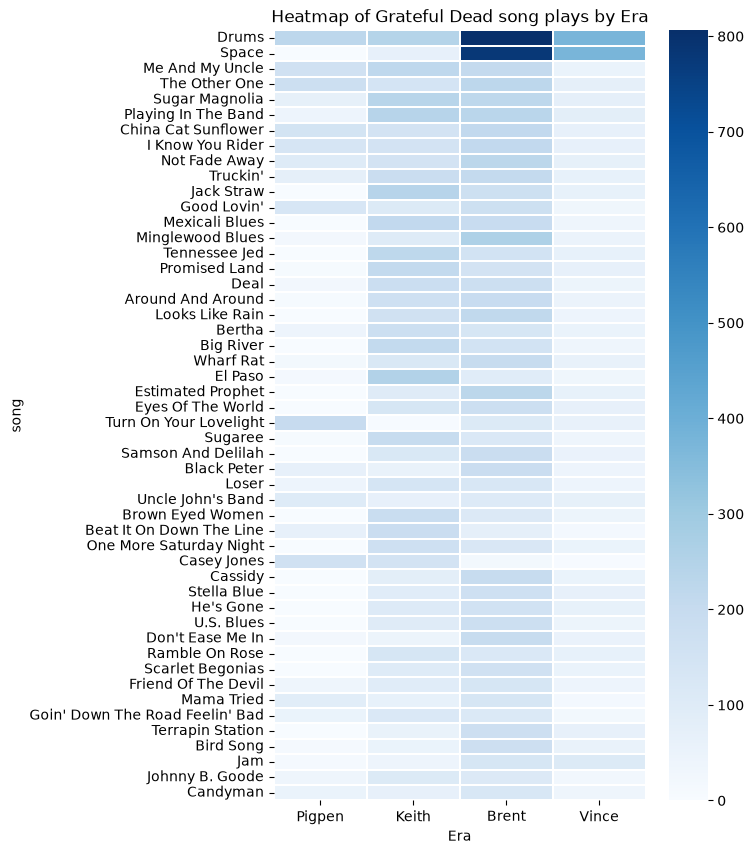

In [64]:
plt.figure(figsize=(6,10))
sns.heatmap(heatmap_data,cmap='Blues',linewidths=0.3)
plt.title('Heatmap of Grateful Dead song plays by Era')
plt.show()

One problem we can immediately see from the above heatmap is that drums and space, which were played significantly more than any other songs, significantly skew the data, making it very hard to notice any differences in colour shades for the other songs. This is why we now plot a heatmap that excludes drums and space.

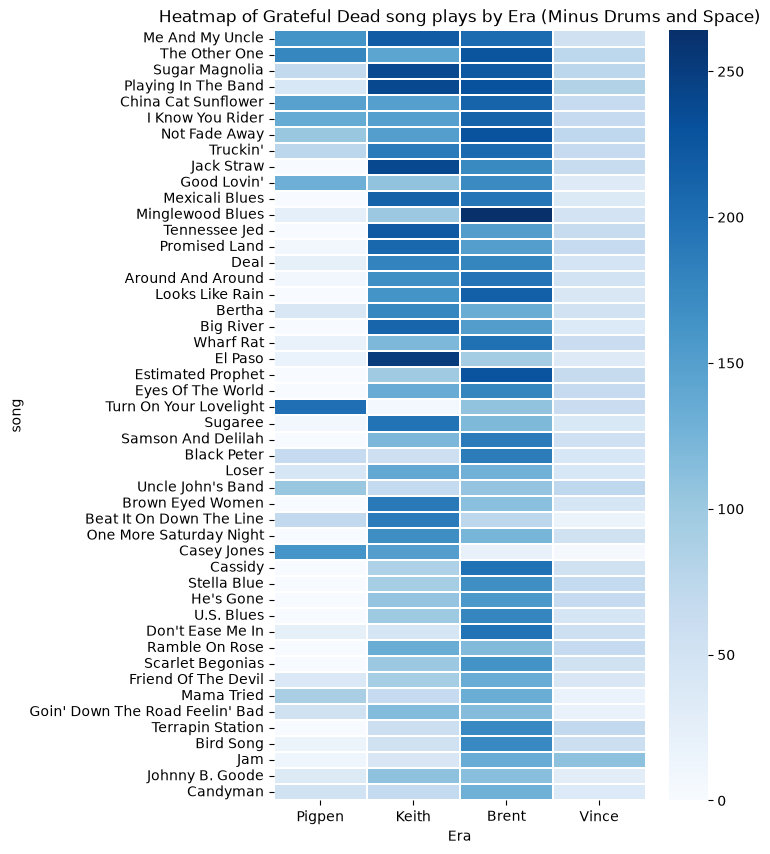

In [65]:
redacted_heatmap_data=heatmap_data.iloc[2:]
plt.figure(figsize=(6,10))
sns.heatmap(redacted_heatmap_data,cmap='Blues',linewidths=0.3)
plt.title('Heatmap of Grateful Dead song plays by Era (Minus Drums and Space)')
plt.show()

While the above heatmaps which rely on pure abundance are interesting, if we want to find interesting trends in songs over their different eras, we need to plot the songs against the percentage of times they were played in a set. This helps normalise against some era's having more shows, so we can better compare between eras.

In [66]:
new_heatmap_data = song_eras_melted.pivot(index='song', columns='Era', values='plays_per_show')
total_heatmap_data=new_heatmap_data
new_heatmap_data=new_heatmap_data.loc[top_50_songs] 
era_order = ['Pigpen', 'Keith', 'Brent', 'Vince']
new_heatmap_data = new_heatmap_data[era_order]

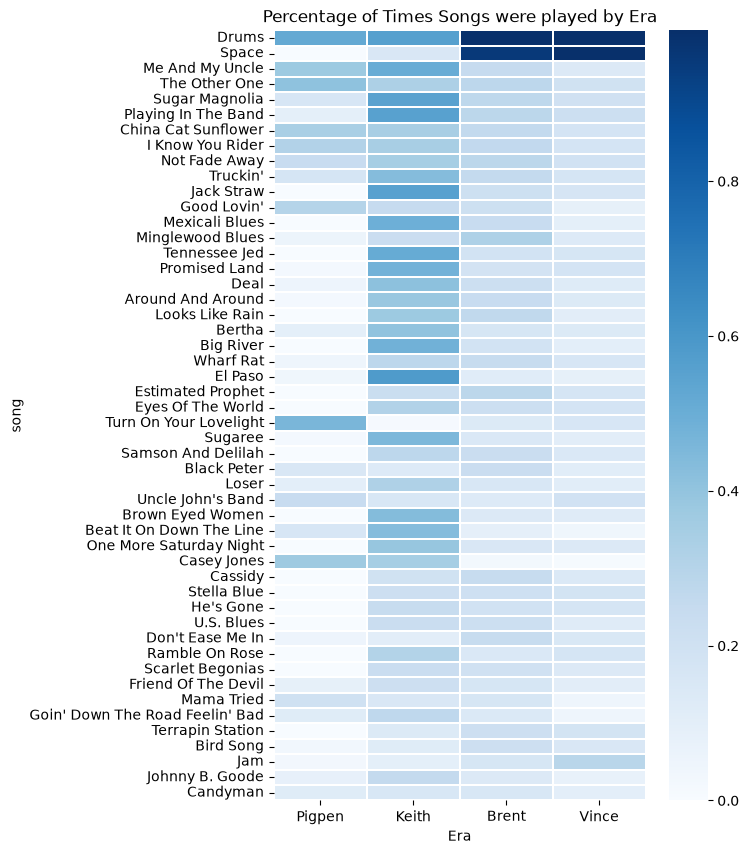

In [67]:
plt.figure(figsize=(6,10))
sns.heatmap(new_heatmap_data,cmap='Blues',linewidths=0.3)
plt.title('Percentage of Times Songs were played by Era')
plt.show()

Once again, we plot the heatmap removing drums and space.

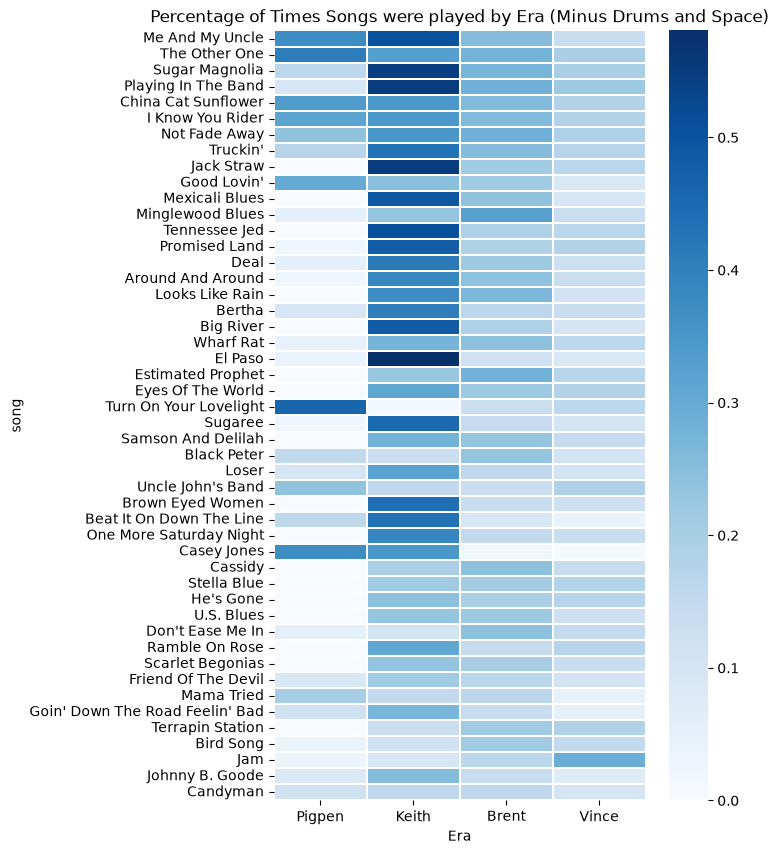

In [68]:
new_redacted_heatmap=new_heatmap_data[2:]
plt.figure(figsize=(6,10))
sns.heatmap(new_redacted_heatmap,cmap='Blues',linewidths=0.3)
plt.title('Percentage of Times Songs were played by Era (Minus Drums and Space)')
plt.show()

We now create a new heatmap where the color intensity is adjusted for the average times a song is played in an era. To do this we first need to work out the average number of plays a song has in a given era, assuming it is played at least once. The numbers represent what times more likely they were to play that song in that era compared to the average song that is played at least once in the era.This helps remove the problem we had where the colours were consistently darker in Keith's era due to them playing very long sets, so the colours appear darker.

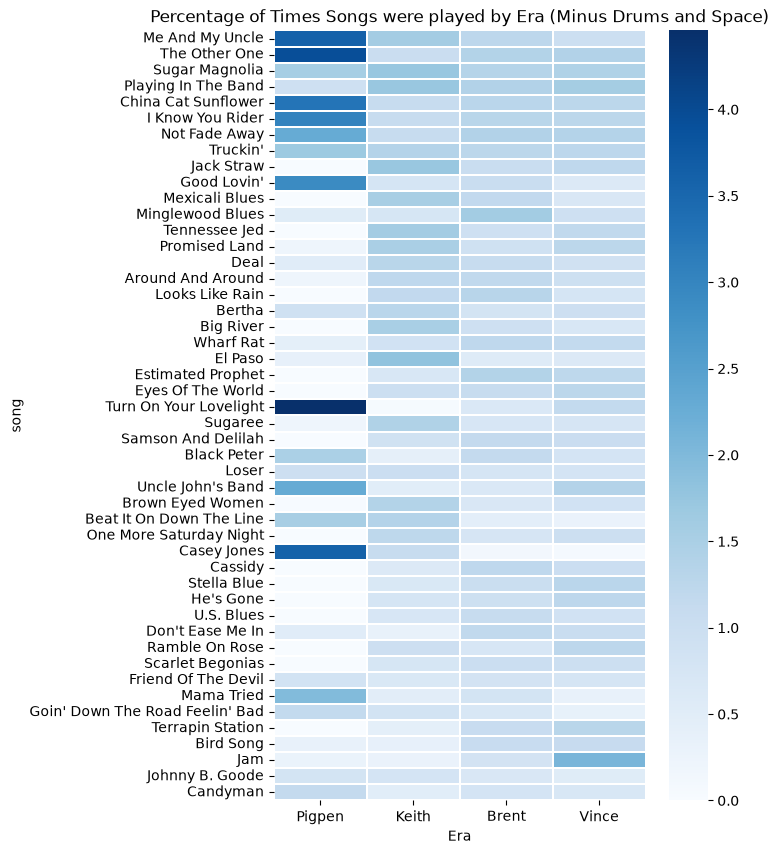

In [69]:
era_order = ['Pigpen', 'Keith', 'Brent', 'Vince']
total_heatmap_data = total_heatmap_data[era_order]
total_replaced_data=total_heatmap_data.replace(0,np.nan)
era_averages=total_replaced_data.mean(axis=0)

era_cols = ['Pigpen', 'Keith', 'Brent', 'Vince']
era_averages = new_redacted_heatmap[era_cols].mean()
relative_heatmap = new_redacted_heatmap[era_cols].div(era_averages, axis=1)
plt.figure(figsize=(6,10))
sns.heatmap(relative_heatmap,cmap='Blues',linewidths=0.3)
plt.title('Ratio of Times Songs were played by Era Compared To Average')
plt.show()

Now we use out heatmap data to pick out some songs with interesting trends.
For example, plotting Turn On Your Lovelight showcases it as a song that was incredibly popular early on, fell off and had somewhat of a resurgence later in the bands career. 

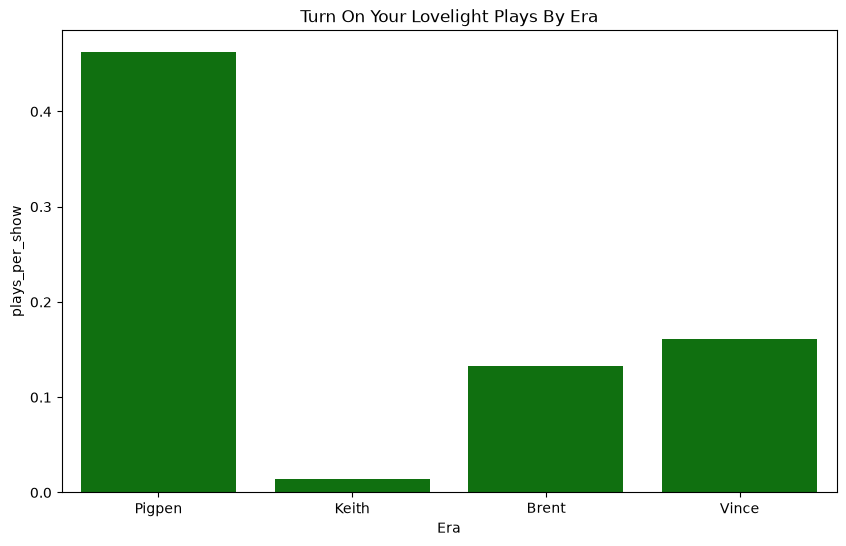

In [70]:
song_by_era('Turn On Your Lovelight')

Now, plotting The Other One we can see it as a song that stays quite popular for the bands entire run.

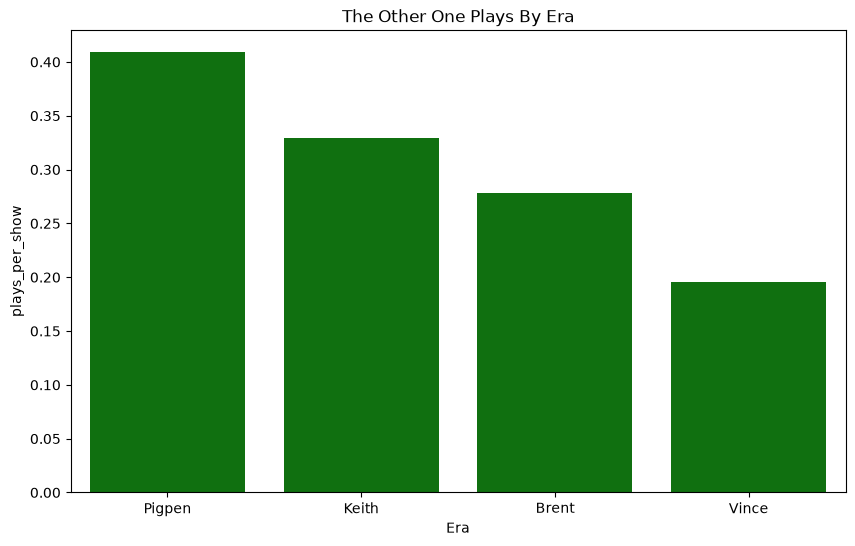

In [71]:
song_by_era('The Other One')

We can see Casey Jones is an example of a song that is very popular early on, before falling off very fast.

Era
Pigpen    3.587744
Keith     1.093378
Brent     0.121967
Vince     0.075680
Name: Casey Jones, dtype: float64


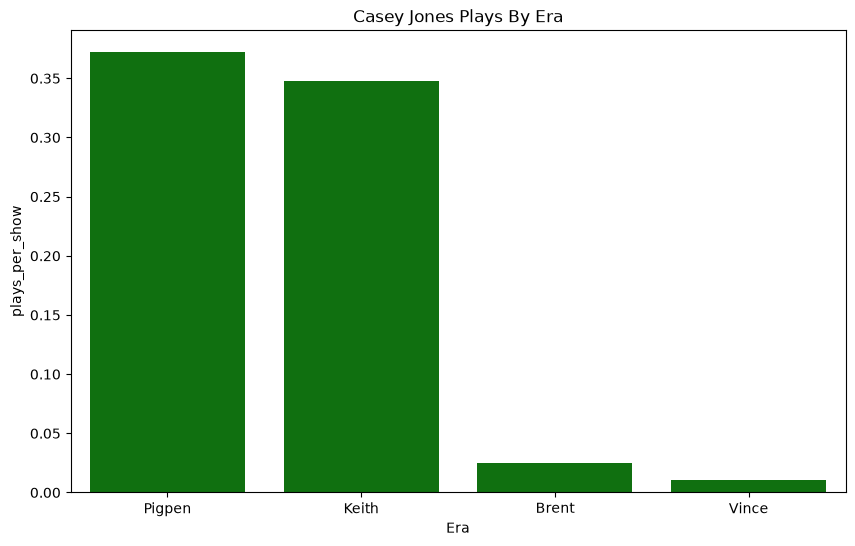

In [72]:
print(relative_heatmap.loc['Casey Jones'])
song_by_era('Casey Jones')

Bird Song is an example of a song that started as a rarity and became more popular as time went on.

Era
Pigpen    0.334262
Keith     0.376527
Brent     1.067209
Vince     1.097359
Name: Bird Song, dtype: float64


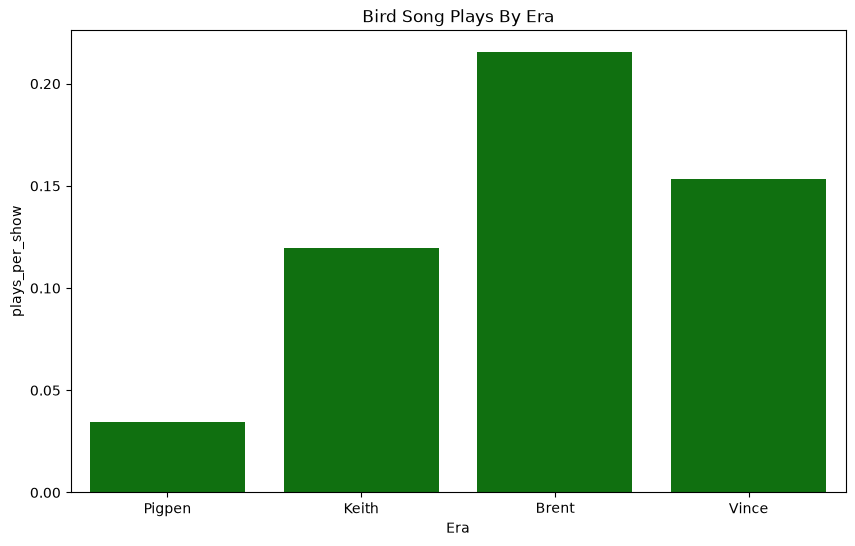

In [73]:
print(relative_heatmap.loc['Bird Song']) 
song_by_era('Bird Song')

Now, we move on to the Markov Chain portion of the project. Our goal is to model the transtion probabilities between songs, to see if we could build a model that would be able to meaningfully predict what song comes next in a set, based solely on the song that has just been played. 

We start by creating a new column in our dataset that contains the name of the song that comes after it in the set. We remove the songs that come at the end of a set. Then we group our transitions together to get the count for how often every transition happened.

In [74]:
gd_markov=gd_setlists_markov
gd_markov['next_song'] = gd_markov.groupby(['date', 'venue', 'true_set_sequence'])['song'].shift(-1)
#Removes the songs that come at the end of a set
gd_markov=gd_markov[gd_markov['next_song'].notnull()]

In [75]:
#Groups the transitions that occur by groups and then reset it to a normal table.
transition_counts = gd_markov.groupby(['song', 'next_song']).size().reset_index()
#Rename the column count that currently has no name
transition_counts=transition_counts.rename(columns={transition_counts.columns[2]:'Count'})
#We can see by the value in the I Know You Rider column that this has worked
print(transition_counts[transition_counts['song']=='China Cat Sunflower'].head(50))

                     song                    next_song  Count
1110  China Cat Sunflower                Crazy Fingers      1
1111  China Cat Sunflower             Cumberland Blues      1
1112  China Cat Sunflower               Doin' That Rag      5
1113  China Cat Sunflower                  Good Lovin'      1
1114  China Cat Sunflower                    High Time      2
1115  China Cat Sunflower             I Know You Rider    537
1116  China Cat Sunflower                   Mama Tried      1
1117  China Cat Sunflower                  Morning Dew      2
1118  China Cat Sunflower           New Potato Caboose      1
1119  China Cat Sunflower  Sitting On Top Of The World      1
1120  China Cat Sunflower                   The Eleven      9


We create our matrix using our transition counts and fill in the values for transitions that never happened as zeroes.

In [76]:
#We make our transition matrix
matrix=transition_counts.pivot(index='song',columns='next_song',values='Count') 
matrix = matrix.fillna(0)
print(matrix)

next_song                 (I'm A) Road Runner  A Mind To Give Up Livin'  \
song                                                                      
(I'm A) Road Runner                       0.0                       0.0   
A Mind To Give Up Livin'                  0.0                       0.0   
A Voice From On High                      0.0                       0.0   
Alabama Getaway                           0.0                       0.0   
Alice D. Millionaire                      0.0                       0.0   
...                                       ...                       ...   
Willie And The Hand Jive                  0.0                       0.0   
You Ain't Woman Enough                    0.0                       0.0   
You Don't Have To Ask                     0.0                       0.0   
You Don't Love Me                         0.0                       0.0   
You Win Again                             0.0                       0.0   

next_song               

We have the problem that the matrix is not square, as some songs are never transitioned into or never transition into anything.
We remedy this by creating a set of all songs and then reindexing the matrix to include them, filling their rows or columns with zeroes.

In [77]:
songs_as_current = set(transition_counts['song'])
songs_as_next = set(transition_counts['next_song'])
all_songs=sorted(songs_as_current | songs_as_next)
matrix = matrix.reindex(index=all_songs, columns=all_songs, fill_value=0)

Next, we need to fix the issue that our matrix contains lots of values that are zero. It would not make sense to leave to leave all of these values as zeroes as just because a transition never actually occurred doesn't mean that the probability of it occuring was truly zero. To fix this, we use laplace smoothing on our matrix. To do this I picked alpha=0.05 which seemed sensible, and later in the project we show that this a mathematically sound value to use.

In [78]:
#Now we do laplace smoothing to represent the probability that a song was transitioned into is never truly 0
alpha=0.05
N=matrix.shape[1]

#Create a list of the amount of times each song transitions to another one over their career, adding in empty columns for those songs who never do
total_counts=transition_counts.groupby(['song'])['Count'].sum()
total_counts = total_counts.reindex(all_songs, fill_value=0)

#Creates the numerator and denominator for laplace smoothing and calculates the probability matrix.
numerator=matrix+alpha
denominator=total_counts+(alpha*N)
prob_matrix=numerator.div(denominator,axis=0)

#Checks that a transition that should be very big is indeed high
print(prob_matrix.loc['China Cat Sunflower','I Know You Rider'])
#Checks the sum of each row equals 1 to make sure it worked.
colsum=prob_matrix.sum(axis=1)
print(colsum.sum(axis=0))


0.9226870543767718
421.0000000000007


Now, we move on to computing the stationary distribution for our matrix, which we can then use to predict our song transitions and see if our model has any real predictive power. To do this, we use Numpy's built in linear algebra module that lets us compute the eigenvalues and eigenvectors for our matrix.

In [79]:
import numpy as np
P=prob_matrix.to_numpy()
eigenvalues, eigenvectors = np.linalg.eig(P.T)

#We can see that the first eigenvalue is our eigenvalue that is incredibly close to 1 
print(eigenvalues)

[ 1.00000000e+00+0.00000000e+00j  6.43556169e-01+0.00000000e+00j
 -5.98665519e-01+0.00000000e+00j  4.91949846e-01+0.00000000e+00j
  1.25003732e-01+3.61835936e-01j  1.25003732e-01-3.61835936e-01j
  3.25790105e-01+1.75671188e-01j  3.25790105e-01-1.75671188e-01j
  3.48477513e-01+0.00000000e+00j -1.76759249e-01+2.87218057e-01j
 -1.76759249e-01-2.87218057e-01j -3.20298994e-01+0.00000000e+00j
  2.45014654e-01+6.19744437e-02j  2.45014654e-01-6.19744437e-02j
 -2.68733543e-01+9.83363473e-02j -2.68733543e-01-9.83363473e-02j
  2.22415224e-01+3.14738293e-02j  2.22415224e-01-3.14738293e-02j
  1.59264563e-01+1.37960578e-01j  1.59264563e-01-1.37960578e-01j
  3.26705198e-02+2.15853870e-01j  3.26705198e-02-2.15853870e-01j
  1.72502875e-01+0.00000000e+00j  1.47323849e-01+7.29336720e-02j
  1.47323849e-01-7.29336720e-02j  7.13259355e-02+1.60439829e-01j
  7.13259355e-02-1.60439829e-01j  2.87335715e-02+1.78512024e-01j
  2.87335715e-02-1.78512024e-01j -1.33982390e-01+1.60741415e-01j
 -1.33982390e-01-1.607414

We extract the eigenvalue that is 1 and then normalise the corresponding eigenvector to get the stationary distribution.

In [80]:
eigen=eigenvalues.real[0]
eigvect=eigenvectors[:,0]
norm=np.linalg.norm(eigvect)
stat_vec=eigvect/norm
stat_vec=stat_vec.real
stat_vec = stat_vec / stat_vec.sum()
print(stat_vec.sum())

1.0


We turn our stationary distribution into a series and compare it to a list of the most played songs. We can see that the lists are very similar which gives immense encouragement that our stationary distribution has indeed worked. 

In [81]:
stationary_dist = pd.Series(stat_vec, index=prob_matrix.index,name='stat_prob')
print(stationary_dist.sort_values(ascending=False).head(20))
gd_setlists.groupby(['song'])['song'].value_counts().sort_values(ascending=False).head(20)

song
Drums                              0.045202
Space                              0.031916
Not Fade Away                      0.019701
The Other One                      0.016268
Playing In The Band                0.016173
Sugar Magnolia                     0.015761
Good Lovin'                        0.013939
Me And My Uncle                    0.013930
Goin' Down The Road Feelin' Bad    0.011880
Around And Around                  0.011360
Turn On Your Lovelight             0.011278
Wharf Rat                          0.010832
Truckin'                           0.010827
Deal                               0.010503
Mexicali Blues                     0.010478
Black Peter                        0.010398
Tennessee Jed                      0.009510
El Paso                            0.009325
Stella Blue                        0.009236
Looks Like Rain                    0.009040
Name: stat_prob, dtype: float64


song
Drums                     1781
Space                     1246
Playing In The Band        753
The Other One              665
Not Fade Away              660
Me And My Uncle            641
Sugar Magnolia             606
China Cat Sunflower        575
I Know You Rider           567
Truckin'                   539
Good Lovin'                536
Jack Straw                 477
Mexicali Blues             442
Minglewood Blues           438
Tennessee Jed              436
Promised Land              435
Turn On Your Lovelight     430
Deal                       428
Around And Around          422
Looks Like Rain            418
Name: count, dtype: int64

Our next step is to confirm whether our model actually has any predictive power. To do this we use a validation technique, by repeating our model, this time on the dataset with a random 20% of sets removed. After this, we test the model on the other 20% of sets and see if it is any good at predicting what song actually came next in the set. To do this, our first port of call is to split our data into the training and test data.

In [82]:
import random
np.random.seed(12345)
random.seed(12345)

#Creates a list of all of the shows that the grateful dead played
shows=gd_markov[['date','venue']].drop_duplicates()
shows=shows.reset_index(drop=True)
print(shows)

#Creates a random sample of 20% of the shows that we want to exclude from our training data
length=shows.shape[0]
rems=int(length*0.2)
import random
ranlist=random.sample(range(1, length), rems)

#Splits our shows into shows we train on and shows we then test on
test_shows=shows.loc[ranlist].sort_values(['date'])
training=shows.drop(ranlist)
print(test_shows)

            date                                         venue
0     1966-01-07                     Matrix, San Francisco, CA
1     1966-02-25               Empire Studios, Los Angeles, CA
2     1966-05-19            Avalon Ballroom, San Francisco, CA
3     1966-07-03        Fillmore Auditorium, San Francisco, CA
4     1966-07-16        Fillmore Auditorium, San Francisco, CA
...          ...                                           ...
1922  1995-07-02      Deer Creek Music Center, Noblesville, IN
1923  1995-07-05  Riverport Amphitheatre, Maryland Heights, MO
1924  1995-07-06  Riverport Amphitheatre, Maryland Heights, MO
1925  1995-07-08                    Soldier Field, Chicago, IL
1926  1995-07-09                    Soldier Field, Chicago, IL

[1927 rows x 2 columns]
            date                                        venue
5     1966-07-17       Fillmore Auditorium, San Francisco, CA
7     1966-07-30  P.N.E. Garden Auditorium, Vancouver, Canada
8     1966-11-19       Fillmore A

We now need to remove the songs from the markov dataset that are not in the training data. We do this by creating a showid column in both datasets and filtering out the shows that are not in the training dataset.

In [83]:
gd_markov['show_id']=gd_markov['date']+gd_markov['venue']
training['show_id']=training['date']+training['venue']

markov_mask=(gd_markov['show_id'].isin(training['show_id']))
gd_training=gd_markov[markov_mask]

In [84]:
#we run a quick sanity to check to make sure roughly 20% of the songs have been removed.
print(gd_markov.shape[0])
print(gd_training.shape[0])

33768
26937


Now, we run the same setup as before on our training data, which we'll use to obtain our new transition matrix.

In [85]:
train_trans_counts = gd_training.groupby(['song', 'next_song']).size().reset_index()
#Renames the column count that currently has no name
train_trans_counts=train_trans_counts.rename(columns={train_trans_counts.columns[2]:'Count'})

print(transition_counts[transition_counts['song']=='China Cat Sunflower'].head(8))
print(train_trans_counts[train_trans_counts['song']=='China Cat Sunflower'].head(8))

                     song         next_song  Count
1110  China Cat Sunflower     Crazy Fingers      1
1111  China Cat Sunflower  Cumberland Blues      1
1112  China Cat Sunflower    Doin' That Rag      5
1113  China Cat Sunflower       Good Lovin'      1
1114  China Cat Sunflower         High Time      2
1115  China Cat Sunflower  I Know You Rider    537
1116  China Cat Sunflower        Mama Tried      1
1117  China Cat Sunflower       Morning Dew      2
                     song           next_song  Count
999   China Cat Sunflower       Crazy Fingers      1
1000  China Cat Sunflower    Cumberland Blues      1
1001  China Cat Sunflower      Doin' That Rag      4
1002  China Cat Sunflower           High Time      2
1003  China Cat Sunflower    I Know You Rider    425
1004  China Cat Sunflower          Mama Tried      1
1005  China Cat Sunflower         Morning Dew      2
1006  China Cat Sunflower  New Potato Caboose      1


We repeat the same process as before to make sure our matrix is square, taking special care to get the songs from the previous transition matrix, not this one because some songs may be in our total dataset but removed from our training dataset.

In [86]:
new_matrix=train_trans_counts.pivot(index='song',columns='next_song',values='Count') 
new_matrix = new_matrix.fillna(0)

songs_as_current = set(transition_counts['song'])
songs_as_next = set(transition_counts['next_song'])
all_songs=sorted(songs_as_current | songs_as_next)
new_matrix =new_matrix.reindex(index=all_songs, columns=all_songs, fill_value=0)

Now, we can create our new proability matrix that we'll use for testing.

In [87]:
alpha=0.05
N=new_matrix.shape[1]

#Create a list of the amount of times each song transitions to another one over their career, adding in empty columns for those songs who never do
new_total_counts=train_trans_counts.groupby(['song'])['Count'].sum()
new_total_counts = new_total_counts.reindex(all_songs, fill_value=0)

#Creates the numerator and denominator for laplace smoothing and calculates the probability matrix.
numerator=new_matrix+alpha
denominator=new_total_counts+(alpha*N)
new_prob_matrix=numerator.div(denominator,axis=0)

#Checks that a transition that should be very big is indeed high
print(new_prob_matrix.loc['China Cat Sunflower','I Know You Rider'])
#Checks the sum of each row equals 1 to make sure it worked.
colsum=new_prob_matrix.sum(axis=1)
print(colsum.sum(axis=0))

0.9120266065872761
421.0000000000007


Now, we complete our testing. We first obtain our testing data, before defining a function that returns a list of the top 5 transition probabilities for a given song. Then we apply this function to each song in our matrix to get the top 5 songs that each song is likely to transition to, based on our transition matrix. It makes more sense for our data that we count our model as succesful if its in the top 5 played songs rather than just the top one, due to the sheer amount of songs its possible to transition into.

In [88]:
#We get the portion of our dataset that isn't in out training data
test_trans=gd_markov[~markov_mask]
#Define a function that gives us a list of the top 5 transition probabilities 
def top_5(row):
    return row.nlargest(5).index.tolist()
#Applies that function to each row to give a list of the top 5 songs that each song transition into
top5=new_prob_matrix.apply(top_5,axis=1)
print(top5)

song
(I'm A) Road Runner         [Dupree's Diamond Blues, West L.A. Fadeaway, (...
A Mind To Give Up Livin'    [Turn On Your Lovelight, (I'm A) Road Runner, ...
A Voice From On High        [Swing Low Sweet Chariot, (I'm A) Road Runner,...
Alabama Getaway             [Promised Land, Greatest Story Ever Told, John...
Alice D. Millionaire        [Me And My Uncle, (I'm A) Road Runner, A Mind ...
                                                  ...                        
Willie And The Hand Jive    [Candyman, Goin' Down The Road Feelin' Bad, Ik...
You Ain't Woman Enough      [El Paso, Jack Straw, Bird Song, Box Of Rain, ...
You Don't Have To Ask       [Big Boss Man, Cold Rain And Snow, Midnight Ho...
You Don't Love Me           [Beat It On Down The Line, (I'm A) Road Runner...
You Win Again               [Jack Straw, Not Fade Away, El Paso, Mexicali ...
Length: 421, dtype: object


We use this table to run through our testing data, and see count for each song whether its next song is in our predicted top 5. We count these total amount of hits and calculate the percentage of times we got a hit. This comes out as 49.2%, which for a transition matrix with 421 values is very high, showing our model has decent predictive power.

In [89]:
#We run through our testing data, seeing if the actual next song played is in the top 5 that our model would predict
hits = [next_song in top5[song] for song, next_song in zip(test_trans['song'], test_trans['next_song'])]
print("The top 5 accuracy is "+str(np.mean(hits).round(3)))

The top 5 accuracy is 0.492


Now, we move to calculating what the best alpha is to use in our laplace smoothing. To do this, we create a function that calculate the log likelihood.

In [90]:
#We build the log-likelihood of our model.
#This will be used to fine tune alpha and check our matrix is good
probs = []
for index, row in test_trans.iterrows():
    probability = new_prob_matrix.loc[row['song'], row['next_song']]
    probs.append(probability)
model_ll = np.mean(np.log(probs))
print(model_ll)

-3.502933164624046


We run the above likelihood model with different values of alpha and get the following results in order to test which value creates the highest likelihood for our model.

In [91]:
#We want to check what value of alpha gives us the log likelihood with smallest magnitude
likelihoods=[-3.821,-3.58,-3.504,-3.503,-3.505,-3.53,-3.69]
alphas=[0.001,0.01,0.04,0.05,0.06,0.1,0.3] 
for i in range(0,len(alphas)):
    print('When I run the log-likelihood with alpha='+str(alphas[i])+' we get a likelihood of '+str(likelihoods[i]))
print('So we pick alpha=0.05 as the optimal for our model from these choices')

When I run the log-likelihood with alpha=0.001 we get a likelihood of -3.821
When I run the log-likelihood with alpha=0.01 we get a likelihood of -3.58
When I run the log-likelihood with alpha=0.04 we get a likelihood of -3.504
When I run the log-likelihood with alpha=0.05 we get a likelihood of -3.503
When I run the log-likelihood with alpha=0.06 we get a likelihood of -3.505
When I run the log-likelihood with alpha=0.1 we get a likelihood of -3.53
When I run the log-likelihood with alpha=0.3 we get a likelihood of -3.69
So we pick alpha=0.05 as the optimal for our model from these choices


We test our hit rate against the baseline of always assuming the next song will be from the top 5 most played songs. We calculate this and get the percentage hitrate of 14.6%, showing that our model is indeed better than a simple model.

In [92]:
#We test what the hit rate would be if the model guessed that the next song would just be from the top 5 most popular songs
top5_baseline = train_trans_counts.groupby('next_song')['Count'].sum().nlargest(5).index
baseline_hit = test_trans['next_song'].isin(top5_baseline).mean()
print(baseline_hit)

0.14624505928853754
